# `SECCOM_2026`

# [bit.ly/4i2BZFK](https://bit.ly/4i2BZFK)

# 📈 Optimização Quântica com Ket

In [1]:
from typing import Callable
from functools import partial
from functools import reduce
from operator import add

from scipy.optimize import minimize, OptimizeResult
import networkx as nx
import matplotlib.pyplot as plt
from IPython.display import display

from ket import *
from ket import ket_version

ket_version()

['Ket v0.10.4.2',
 'libket v0.7.1 [rustc 1.97.1 (8bab26f4f 2026-07-14) x86_64-unknown-linux-gnu]',
 'kbw v0.5.1 [GPU, CUDA] [rustc 1.97.1 (8bab26f4f 2026-07-14) x86_64-unknown-linux-gnu]']

# Quantum Approximate Optimization Algorithm

O _Quantum Approximate Optimization Algorithm_ (QAOA) é um algoritmo quântico variacional que visa encontrar soluções aproximadas para problemas de otimização combinatória. Sendo um método híbrido (quântico-clássico) desenvolvido com o intuito de executar em dispositivos de curto prazo (NISQ), ele pode ser visto como uma versão discretizada da computação quântica adiabática.

![](https://ar5iv.labs.arxiv.org/html/2306.09198/assets/learning_process.svg)

O funcionamento básico do algoritmo consiste em preparar um estado inicial uniforme e submetê-lo a $p$ camadas alternadas de evolução unitária. Ao final, o circuito é medido e os parâmetros dessa evolução são ajustados classicamente. Os três blocos construtores principais que possibilitam esse funcionamento são:

## Hamiltoniano do Problema ($H_C$)

Este bloco codifica a função objetivo (ou custo) do problema clássico a ser resolvido.

- **O que faz:** As variáveis de decisão do problema são tipicamente mapeadas para operadores de Pauli-Z na base computacional. A configuração que soluciona o problema de otimização corresponde ao autoestado de menor energia deste Hamiltoniano.

- **No circuito:** A evolução governada pelo Hamiltoniano do problema:
  $$\hat U_C(\gamma_k) = e^{-i\gamma_k H_C}$$


## Hamiltoniano de Mistura ($H_M$)

Para explorar o espaço de busca e garantir que o sistema crie transições entre as soluções, introduz-se o Hamiltoniano de mistura.

- **O que faz:** O requisito essencial de $H_M$ é que ele **não comute** com o Hamiltoniano do problema $H_C$. Na sua implementação padrão, ele é definido como a soma de operadores Pauli-X atuando em todos os qubits.

- **No circuito:** O operador de mistura atua criando transições entre as diferentes configurações da base computacional:
  $$\hat U_M(\beta_k) = e^{-i\beta_k H_M}$$
  


## Otimizador Clássico

A busca iterativa de parâmetros ótimos é responsabilidade para um processador clássico.

- **O que faz:** A medição do estado final do circuito quântico fornece o valor esperado da função de custo: $F(\gamma, \beta) = \langle\psi(\gamma, \beta)|H_C|\psi(\gamma, \beta)\rangle$. O otimizador clássico avalia esse resultado estatístico e calcula um novo conjunto de ângulos $\gamma$ e $\beta$ para minimizar o valor esperado na próxima iteração do circuito.

- **Importância:** Uma vez que o otimizador clássico convirja para o conjunto ideal de parâmetros $(\gamma, \beta)$ , o circuito produzirá, com alta probabilidade, o estado quântico que codifica a solução aproximada do problema. A escolha correta da rotina clássica é fundamental para contornar mínimos locais e mitigar o problema como _barren plateaus_.


## Implementação usando Ket  

In [2]:
def qaoa_layer(
    problem_h: Callable[[Quant], Hamiltonian],
    mixer_h: Callable[[Quant], Hamiltonian],
    qubits: Quant,
    gamma: float,
    beta: float,
):
    """
    Aplica uma única camada (p=1) do Ansatz QAOA aos qubits fornecidos.

    Args:
        problem_h: Função que recebe os qubits alocados e retorna o Hamiltoniano do problema (função custo).
        mixer_h: Função que recebe os qubits alocados e retorna o Hamiltoniano de mistura.
        qubits: Referência para os qubits alocados no processo atual.
        gamma: Parâmetro variacional associado à evolução do Hamiltoniano do problema.
        beta: Parâmetro variacional associado à evolução do Hamiltoniano de mistura.
    """
    evolve(problem_h(qubits) * gamma)
    evolve(mixer_h(qubits) * beta)


def ansatz(
    problem_h: Callable[[Quant], Hamiltonian],
    mixer_h: Callable[[Quant], Hamiltonian],
    initial_state: Callable[[any], None],
    qubits: Quant,
    gamma: list[float],
    beta: list[float],
):
    """
    Constrói o circuito quântico completo do QAOA, aplicando o estado inicial
    e as 'p' camadas de evolução alternada.

    Args:
        problem_h: Função geradora do Hamiltoniano do problema.
        mixer_h: Função geradora do Hamiltoniano de mistura.
        initial_state: Função que prepara o estado inicial apropriado nos qubits
                       (ex: superposição uniforme com portas H, ou Dicke state para Mixer XY).
        qubits: Referência para os qubits do circuito.
        gamma: Lista com os 'p' parâmetros variacionais gamma.
        beta: Lista com os 'p' parâmetros variacionais beta.
    """
    initial_state(qubits)
    for g, b in zip(gamma, beta):
        qaoa_layer(problem_h, mixer_h, qubits, g, b)


def qaoa(
    problem_h: Callable[[Quant], Hamiltonian],
    mixer_h: Callable[[Quant], Hamiltonian],
    initial_state: Callable[[any], None],
    num_qubits: int,
    p: int,
    dt: float = 0.5,
    method: str = "COBYLA",
) -> tuple[OptimizeResult, Samples]:
    """
    Executa o loop de otimização híbrido (clássico-quântico) do QAOA.

    Inicializa os parâmetros inspirando-se em um processo de quantum annealing
    (gamma crescente, beta decrescente) e utiliza um otimizador clássico para
    encontrar a configuração que minimiza o valor esperado do Hamiltoniano do problema.

    Args:
        problem_h: Função geradora do Hamiltoniano do problema.
        mixer_h: Função geradora do Hamiltoniano de mistura.
        initial_state: Função de preparação do estado inicial.
        num_qubits: Número total de qubits necessários para o problema.
        p: Número de camadas (profundidade) do Ansatz QAOA.
        dt: Fator de escala para a heurística de inicialização dos parâmetros (padrão: 0.5).
        method: Algoritmo de otimização clássica do SciPy a ser utilizado (padrão: "COBYLA").

    Returns:
        Um tupla contendo:
        - O objeto OptimizeResult retornado pelo SciPy com os detalhes da otimização.
        - A amostragem final do estado otimizado (medidas e contagens).
    """

    def objective(parameters, final=False):
        gamma = parameters[:p]
        beta = parameters[p:]

        # Instancia um novo Processo Ket em batch para execução eficiente
        process = Process(
            num_qubits=num_qubits,
            execution="batch",
            simulator="dense",
        )
        qubits = process.alloc(num_qubits)
        ansatz(problem_h, mixer_h, initial_state, qubits, gamma, beta)

        if final:
            # Amostra o estado final para recuperar as soluções prováveis
            return sample(qubits, 100)

        # Retorna a energia (valor esperado) para o otimizador clássico
        return exp_value(problem_h(qubits)).get()

    # Heurística de inicialização baseada em annealing
    first_gamma = [i / p * dt for i in range(1, p + 1)]  # Crescente
    first_beta = [(1 - i / p) * dt for i in range(1, p + 1)]  # Decrescente

    # Loop de otimização clássica
    res = minimize(
        objective,
        first_gamma + first_beta,  # Gamma vem primeiro, Beta depois
        method=method,
    )

    # Executa o circuito uma última vez com os parâmetros ótimos para obter a distribuição de probabilidade
    final_sample = objective(res.x, final=True)

    return res, final_sample

# Max-Cut

O problema do **Max-Cut** (Corte Máximo) é um dos problemas tradicionais mais utilizados para demonstrar algoritmos de otimização quântica. Ele é um problema NP-Difícil em grafos, o que significa que, à medida que o número de vértices cresce, resolvê-lo de forma exata em computadores clássicos torna-se impraticável.


In [3]:
def plot_maxcut_graph(
    graph_edges: list[tuple[int, int]],
    num_nodes: int,
    qubits_state: list[int] | int,
):
    """
    Plota o grafo do problema Max-Cut, colorindo nodos de acordo com seus estados
    quânticos e destacando as arestas cortadas. Adiciona rótulos indicando <Z_u Z_v>.

    Args:
        graph_edges: Lista de tuplas representando as arestas do grafo.
        num_nodes: Número total de nodos/qubits.
        qubits_state: Lista onde o índice é o nodo e o valor é o estado (0 ou 1).
    """

    if isinstance(qubits_state, int):
        qubits_state = list(map(int, f"{result.most_frequent_state():0{num_nodes}b}"))

    G = nx.Graph()
    G.add_nodes_from(range(num_nodes))
    G.add_edges_from(graph_edges)

    node_states_latex = {}
    for n in G.nodes():
        state_val = qubits_state[n]
        node_states_latex[n] = r"|1$\rangle$" if state_val == 1 else r"|0$\rangle$"

    pos = nx.spring_layout(G, seed=42)
    plt.figure(figsize=(7, 5), facecolor="#f0f0f0")

    node_colors = ["#ffcc00" if qubits_state[n] == 1 else "#66ccff" for n in G.nodes()]
    node_labels_dict = {n: f"{n}\n{node_states_latex[n]}" for n in G.nodes()}

    nx.draw_networkx_nodes(
        G,
        pos,
        node_size=3500,
        node_color=node_colors,
        edgecolors="black",
        linewidths=1.5,
    )
    nx.draw_networkx_labels(
        G,
        pos,
        labels=node_labels_dict,
        font_size=12,
        font_family="DejaVu Sans",
        font_weight="bold",
    )

    cut_edges = []
    not_cut_edges = []
    edge_labels = {}

    for u, v in graph_edges:
        if qubits_state[u] != qubits_state[v]:
            cut_edges.append((u, v))
            edge_labels[(u, v)] = f"$\\langle Z_{u}Z_{v} \\rangle = -1$"
        else:
            not_cut_edges.append((u, v))
            edge_labels[(u, v)] = f"$\\langle Z_{u}Z_{v} \\rangle = +1$"

    nx.draw_networkx_edges(
        G, pos, edgelist=cut_edges, width=6, edge_color="#ff3333", style="solid"
    )
    nx.draw_networkx_edges(
        G, pos, edgelist=not_cut_edges, width=2.5, edge_color="#999999", style="dashed"
    )

    nx.draw_networkx_edge_labels(
        G,
        pos,
        edge_labels=edge_labels,
        font_size=24,
        bbox=dict(facecolor="white", edgecolor="none", pad=3),
    )

    plt.tight_layout()
    plt.show()

## Problema

![](https://ar5iv.labs.arxiv.org/html/2306.09198/assets/maxcut6.png)

Dado um grafo não direcionado $G = (V, E)$, onde $V$ é o conjunto de vértices e $E$ é o conjunto de arestas, o objetivo do Max-Cut é dividir os vértices em dois conjuntos disjuntos (digamos, o conjunto $A$ e o conjunto $B$) de forma que o número de arestas que conectam um vértice em $A$ a um vértice em $B$ seja maximizado. Em outras palavras, queremos "cortar" o maior número possível de arestas ao separar o grafo ao meio.

Para modelar isso em um computador quântico, mapeamos cada vértice do grafo para um qubit. O estado do qubit indicará a qual conjunto o vértice pertence:

- Estado $\left|0 \right>$ $\rightarrow$ Vértice no conjunto $A$.
- Estado $\left|1 \right>$ $\rightarrow$ Vértice no conjunto $B$.


## Hamiltoniano do Max-Cut

Para o QAOA, precisamos de uma função custo que represente a qualidade do nosso corte matematicamente, usando os operadores de Pauli. A ferramenta ideal para isso é o operador Pauli-Z:

- $\left<0|Z|0\right> = +1$
- $\left<1|Z|1\right> = -1$

Se olharmos para dois vértices conectados por uma aresta $(u, v)$, a interação entre eles pode ser medida pelo produto $Z_u Z_v$:

- Se os vértices estão no **mesmo conjunto** ($\left|00\right>$ ou $\left|11\right>$), o produto $Z_u Z_v$ resulta em $+1$.
- Se os vértices estão em **conjuntos diferentes** ($\left|01\right>$ ou $\left|10\right>$), o produto $Z_u Z_v$ resulta em $-1$.

A contribuição de uma única aresta para o corte pode ser formulada como $\frac{1}{2}(1 - Z_u Z_v)$. Essa expressão vale $1$ se a aresta foi cortada, e $0$ se não foi.

O Hamiltoniano total que conta o número de arestas cortadas é a soma dessa expressão sobre todas as arestas do grafo. Como os otimizadores clássicos geralmente buscam **minimizar** a função objetivo, nós multiplicamos o Hamiltoniano por $-1$ para que o estado com o maior número de cortes corresponda à menor energia:

$$H_C = -\frac{1}{2} \sum_{(u,\ v) \in E} (1 - Z_u Z_v)$$


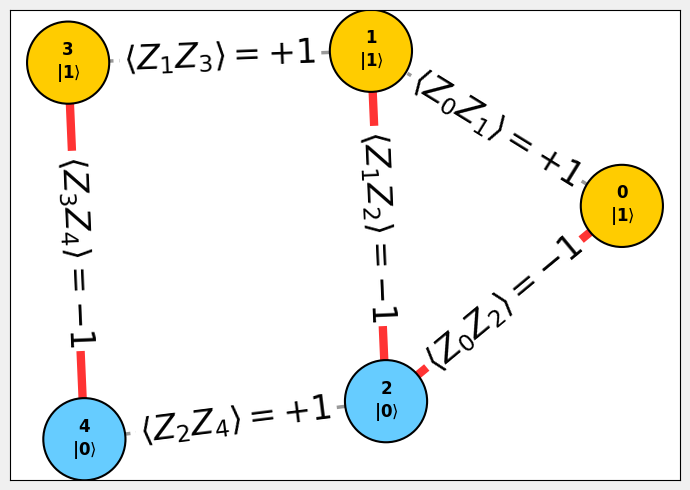

In [4]:
edges = [(0, 1), (0, 2), (1, 2), (1, 3), (2, 4), (3, 4)]
num_nodes = 5

plot_maxcut_graph(edges, num_nodes, [1, 1, 0, 1, 0])

In [5]:
def max_cut_problem_h(edges: list[tuple[int, int]], qubits: Quant) -> Hamiltonian:
    """
    Retorna o Hamiltoniano do problema atrelada a um grafo específico.
    """

    with obs():
        # Retorna a energia negativa do corte (para minimizar)
        return -sum(1 - Z(qubits[u]) * Z(qubits[v]) for u, v in edges) / 2

## Hamiltoniano Padrão

O papel do Hamiltoniano de mistura é permitir que o algoritmo explore diferentes configurações (diferentes divisões dos conjuntos $A$ e $B$).

O operador $X$ atua como um "flip" de bits ($X|0\rangle = |1\rangle$ e $X|1\rangle = |0\rangle$). Ao aplicar a evolução desse Hamiltoniano, o circuito quântico transita entre diferentes configurações de partições do grafo, garantindo que o algoritmo não fique preso em um mínimo local no espaço de busca.

O Hamiltoniano de mistura é simplesmente a soma do operador $X$ atuando individualmente em cada vértice/qubit:

$$H_M = \sum_{k \in V} X_k$$

In [6]:
def default_mixer_h(qubits):
    """
    Hamiltoniano de mistura padrão (Pauli-X em todos os qubits).
    """
    with obs():
        return sum(X(q) for q in qubits)

## Otimizando o Max-Cut

Uma vez definidos os Hamiltonianos do problema e de mistura, basta chamar a função `qaoa` implementada usando Ket.

In [7]:
max_cut = partial(max_cut_problem_h, edges)

res, result = qaoa(
    problem_h=max_cut,
    mixer_h=default_mixer_h,
    initial_state=H,
    num_qubits=num_nodes,
    p=5,
)

print(res)
result.histogram("bin", hamiltonian=max_cut)

 message: Return from COBYLA because the objective function has been evaluated MAXFUN times.
 success: False
  status: 3
     fun: -4.979851603236656
       x: [ 3.943e-01  7.865e-01  8.778e-01  1.005e+00  1.017e+00
            1.019e+00  1.137e+00 -3.454e-01 -2.590e-01 -1.344e-01]
    nfev: 1000
   maxcv: 0.0


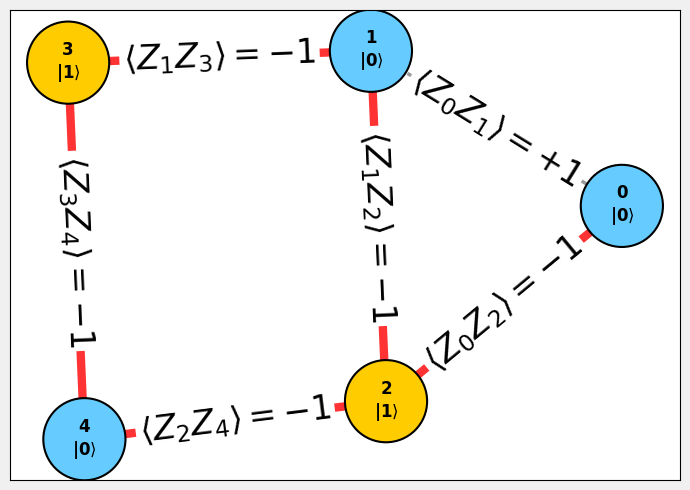

In [8]:
plot_maxcut_graph(edges, num_nodes, result.most_frequent_state())

# Otimização de Portfólio

Na otimização de portfólio, o objetivo de um gestor de investimentos é selecionar um conjunto de ativos financeiros que maximize o retorno esperado ao mesmo tempo em que minimiza o risco de mercado (medido pela covariância entre os ativos), respeitando um limite rígido de orçamento (_budget_).


## Formalismo QUBO

O QUBO (_Quadratic Unconstrained Binary Optimization_) é um problema de otimização matemática abstrato onde o objetivo é minimizar uma função quadrática de variáveis binárias clássicas $x_i \in \{0, 1\}$. A forma geral de uma função de custo QUBO é escrita como:

$$E(x) = \sum_{i} Q_{ii} x_i + \sum_{i < j} Q_{ij} x_i x_j$$

Onde os termos $Q_{ii}$ representam os custos lineares associados a escolher uma variável individualmente, e $Q_{ij}$ representam os custos quadráticos que capturam as interações ou dependências entre pares de decisões.

Para mapear este problema clássico em um circuito quântico, precisamos converter essas variáveis binárias clássicas $\{0, 1\}$ em operadores quânticos cujos autovalores correspondam à base computacional. Fazemos isso utilizando o operador de Pauli-Z, cujos autovalores são $+1$ (para o estado $|0\rangle$) e $-1$ (para o estado $|1\rangle$).

A transformação matemática exata para cada variável é dada por:

$$x_i = \frac{I - Z_i}{2}$$

Substituindo essa relação na equação do QUBO, o problema é transformado diretamente no **Modelo de Ising**, onde passamos a lidar com spins quânticos. Uma das grandes vantagens da plataforma Ket é que ela permite realizar essa álgebra de operadores diretamente no código, poupando de ter que expandir e calcular manualmente os novos coeficientes lineares e quadráticos.


## Problema da Otimização de Portfólio Financeiro

- 📄 [Quantum Finance: um tutorial de computação quântica aplicada ao mercado financeiro](https://doi.org/10.1590/1806-9126-RBEF-2022-0099)

Vamos formular esse problema usando variáveis binárias $x_i$, onde $x_i = 1$ significa que o ativo $i$ será incluído no portfólio, e $x_i = 0$ significa que ele ficará de fora. A função de custo clássica combina três fatores essenciais:

$$H(x) = \underbrace{- \sum_{i=1}^n \mu_i x_i}_{\text{Maximizar Retorno}} + \underbrace{q \sum_{i,j} \sigma_{ij} x_i x_j}_{\text{Minimizar Risco}} + \underbrace{\lambda \left( \sum_{i=1}^n x_i - B \right)^2}_{\text{Restrição (Budget)}}$$

- **Retorno:** Onde $\mu_i$ é o retorno esperado do ativo $i$. O sinal negativo indica que queremos maximizar o retorno (minimizando o custo total).
- **Risco:** Onde $\sigma_{ij}$ representa a covariância entre as variações dos ativos $i$ e $j$, e $q$ é o **fator de aversão ao risco** do investidor.
- **Restrição de Orçamento:** Garante que o número total de ativos selecionados seja exatamente igual ao orçamento $B$. Se a soma das escolhas for diferente de $B$, o termo quadrático aplica uma penalidade severa multiplicada pelo peso de penalização $\lambda$.


In [9]:
def portfolio_optimization_h(
    mu: list[float],
    sigma: list[list[float]],
    budget: int,
    risk_aversion: float,
    penalty: float,
    qubits: Quant,
) -> Hamiltonian:
    """
    Gera O Hamiltoniano do problema para a Otimização de Portfólio Financeiro.
    Mapeia a formulação QUBO clássica para o espaço quântico automaticamente via Ket.

    Args:
        mu: Lista com o retorno esperado de cada ativo.
        sigma: Matriz quadrada de covariância entre os ativos.
        budget: Quantidade exata (B) de ativos que devem ser comprados.
        risk_aversion: Fator de peso 'q' que quantifica a aversão ao risco do investidor.
        penalty: Fator de escala 'lambda' para punir violações do orçamento.
    """
    n = len(mu)

    # 1. Maximizar o Retorno Esperado
    expected_return = sum(mu[i] * B(qubits[i]) for i in range(n))

    # 2. Minimizar a Covariância de Risco
    portfolio_risk = sum(
        sigma[i][j] * B(qubits[i]) * B(qubits[j])
        for i in range(n)
        for j in range(i + 1, n)
    )

    # 3. Aplicar Restrição Rígida de Orçamento (Penalty Term)
    budget_constraint = (sum(B(q) for q in qubits) - budget) ** 2

    # Montagem final da função custo QUBO diretamente combinada no espaço quântico
    h_total = (
        -expected_return + risk_aversion * portfolio_risk + penalty * budget_constraint
    )

    return h_total

## Optimizando o Portfolio


In [10]:
mu = [0.31542042, 0.0571331, 0.11430001, 0.30109367]

sigma = [
    [1.08774352e-03, 2.59532811e-04, 1.80247155e-04, 3.21724369e-04],
    [2.59532811e-04, 4.43192629e-04, 7.43211072e-05, 2.27911525e-04],
    [1.80247155e-04, 7.43211072e-05, 3.89444953e-04, 1.37915422e-04],
    [3.21724369e-04, 2.27911525e-04, 1.37915422e-04, 8.75437564e-04],
]

budget = 2
risk_aversion = 0.5

penalty = 1

portfolio = partial(
    portfolio_optimization_h,
    mu,
    sigma,
    budget,
    risk_aversion,
    penalty,
)

res, result = qaoa(
    problem_h=portfolio,
    mixer_h=default_mixer_h,
    initial_state=H,
    num_qubits=len(mu),
    p=4,
)

## usar mixer XY no problema de otimixzação de portifolio

print(res)
result.histogram("bin", hamiltonian=portfolio)

 message: Return from COBYLA because the trust region radius reaches its lower bound.
 success: True
  status: 0
     fun: -0.37588424517225183
       x: [ 1.087e+00  1.305e+00  1.509e+00  7.634e-01  5.275e-01
            1.204e+00 -5.223e-02  1.151e+00]
    nfev: 896
   maxcv: 0.0


# Coloração de Grafos

O problema da **Coloração de Grafos** consiste em atribuir uma cor a cada vértice de um grafo de modo que nenhum par de vértices adjacentes (conectados por uma aresta) compartilhe a mesma cor, utilizando um número máximo de _k_ cores.

![](https://upload.wikimedia.org/wikipedia/commons/9/90/Petersen_graph_3-coloring.svg)


In [11]:
def plot_k_coloring_graph(
    graph_edges: list[tuple[int, int]],
    num_nodes: int,
    num_colors: int,
    qubits_state: list[int] | int,
):
    """
    Plota o grafo do problema de Coloração, colorindo nodos de acordo com seus estados
    quânticos one-hot e destacando as arestas que apresentam conflito de cores.

    Args:
        graph_edges: Lista de tuplas representando as arestas do grafo.
        num_nodes: Número total de nodos/vértices do grafo.
        num_colors: Número de cores disponíveis (k).
        qubits_state: Lista de (num_nodes * num_colors) estados ou o valor inteiro do estado.
    """

    total_qubits = num_nodes * num_colors

    if isinstance(qubits_state, int):
        qubits_state = list(map(int, f"{qubits_state:0{total_qubits}b}"))

    G = nx.Graph()
    G.add_nodes_from(range(num_nodes))
    G.add_edges_from(graph_edges)

    node_colors_list = []
    node_labels_dict = {}
    node_assigned_color = {}

    palette = ["#ff9999", "#99ccff", "#99ff99", "#ffcc99", "#cc99ff", "#ffff99"]

    for n in G.nodes():
        chunk = qubits_state[n * num_colors : (n + 1) * num_colors]

        ket_str = r"|" + "".join(map(str, chunk)) + r"$\rangle$"
        node_labels_dict[n] = f"{n}\n{ket_str}"

        if sum(chunk) == 1:
            color_idx = chunk.index(1)
            node_assigned_color[n] = color_idx
            node_colors_list.append(palette[color_idx % len(palette)])
        else:
            node_assigned_color[n] = -1
            node_colors_list.append("#cccccc")  # Cinza para destacar erro One-Hot

    pos = nx.spring_layout(G, seed=42)
    plt.figure(figsize=(7, 5), facecolor="#f0f0f0")

    nx.draw_networkx_nodes(
        G,
        pos,
        node_size=3500,
        node_color=node_colors_list,
        edgecolors="black",
        linewidths=1.5,
    )
    nx.draw_networkx_labels(
        G,
        pos,
        labels=node_labels_dict,
        font_size=12,
        font_family="DejaVu Sans",
        font_weight="bold",
    )

    conflict_edges = []
    ok_edges = []
    edge_labels = {}

    for u, v in graph_edges:
        c_u = node_assigned_color.get(u, -1)
        c_v = node_assigned_color.get(v, -1)

        if c_u != -1 and c_v != -1 and c_u == c_v:
            conflict_edges.append((u, v))
            edge_labels[(u, v)] = "CONFLITO"
        else:
            ok_edges.append((u, v))

    nx.draw_networkx_edges(
        G, pos, edgelist=conflict_edges, width=6, edge_color="#ff3333", style="solid"
    )
    nx.draw_networkx_edges(
        G, pos, edgelist=ok_edges, width=2.5, edge_color="#999999", style="dashed"
    )

    if edge_labels:
        nx.draw_networkx_edge_labels(
            G,
            pos,
            edge_labels=edge_labels,
            font_size=14,
            font_color="#ff3333",
            font_weight="bold",
            bbox=dict(facecolor="white", edgecolor="none", pad=3),
        )

    plt.tight_layout()
    plt.show()

## Codificação One-Hot

Diferente do Max-Cut, onde a decisão era binária (conjunto A ou B), aqui cada vértice pode assumir uma entre _k_ cores. Para representar isso nos qubits, utilizamos a codificação **One-Hot**.

Se temos $n$ vértices e $k$ cores, precisaremos de $n \times k$ qubits. Os qubits de um mesmo vértice são agrupados, e a regra de ouro é: apenas um qubit desse grupo pode estar no estado $|1\rangle$, enquanto todos os outros devem estar em $|0\rangle$.

**Exemplo para _k=3_**

- $|100\rangle$ 🔴
- $|010\rangle$ 🟢
- $|001\rangle$ 🔵

![](https://ar5iv.labs.arxiv.org/html/1709.03489/assets/figs/n4graphMap.png)


## Hamiltoniano da $k$-Coloração

Para modelar o problema da coloração de grafos, utilizamos variáveis binárias $x_{u,c} \in \{0, 1\}$, onde $x_{u,c} = 1$ indica que o vértice $u$ recebeu a cor $c$, e $0$ caso contrário. A função de custo clássica (QUBO) que descreve as regras do problema é dividida em duas partes principais:

$$H_C = \overbrace{\sum_{(u,\ v) \in E} \sum_{c} x_{u,c} x_{v,c}}^{\text{Conflitos (Minimizar)}} + A \underbrace{\sum_{v}\left(\sum_{c} x_{v,c} -1\right)^2}_\text{Restrição de Cor Única}$$

### Termo de Conflitos (Penalidade de Aresta)

A primeira parte atua diretamente sobre a topologia do grafo. Para toda aresta conectando os vértices $u$ e $v$ ($(u,\ v) \in E$), e para cada cor possível $c$, verificamos se ambos os vértices receberam essa mesma cor. Se $x_{u,c} = 1$ e $x_{v,c} = 1$, o produto resulta em $1$, somando um "ponto" de penalidade à energia total. O objetivo do otimizador é zerar esse somatório, encontrando uma configuração onde nenhum par de vértices adjacentes compartilhe a mesma cor.

### Restrição de Cor Única (Penalidade de Vértice)

A segunda parte garante que a nossa codificação faça sentido lógico. Para cada vértice $v$, a soma de todas as cores atribuídas a ele ($\sum_{c} x_{v,c}$) deve ser exatamente igual a $1$.

- Se o algoritmo deixar um vértice sem cor (soma $= 0$) ou atribuir mais de uma cor a ele (soma $> 1$), o termo entre parênteses será diferente de zero.
- Ao elevar esse erro ao quadrado e multiplicar por uma constante de penalidade muito alta ($A$), criamos uma barreira de energia que força o otimizador a respeitar a regra de "uma única cor por vértice" (a regra _one-hot_).


In [12]:
def graph_coloring_h(
    edges: list[tuple[int, int]],
    num_nodes: int,
    num_colors: int,
    penalty: int,
    qubits: Quant,
) -> Hamiltonian:

    qubits = [qubits[i * num_colors : (i + 1) * num_colors] for i in range(num_nodes)]

    conflict = sum(
        sum(B(qubits[u][c]) * B(qubits[v][c]) for c in range(num_colors))
        for u, v in edges
    )

    one_hot_restriction = sum(
        (sum(B(qubits[v][c]) for c in range(num_colors)) - 1) ** 2
        for v in range(num_nodes)
    )

    return conflict + penalty * one_hot_restriction

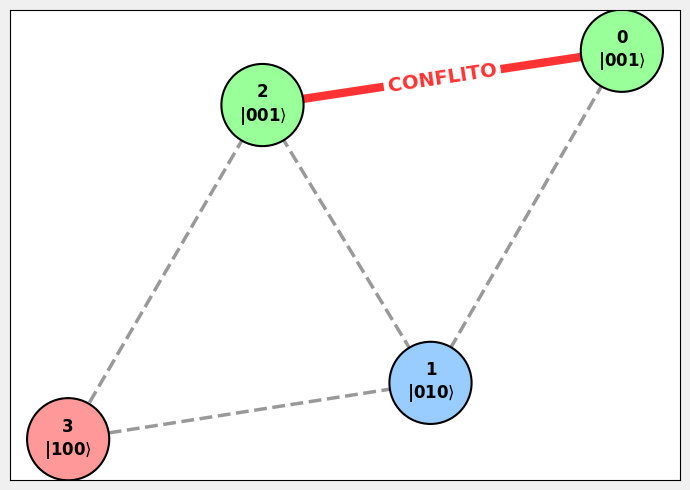

In [13]:
edges = [(0, 1), (0, 2), (1, 2), (1, 3), (2, 3)]
num_nodes = 4
num_colors = 3


plot_k_coloring_graph(
    edges,
    num_nodes,
    num_colors,
    [0, 0, 1, 0, 1, 0, 0, 0, 1, 1, 0, 0],
)

 message: Return from COBYLA because the objective function has been evaluated MAXFUN times.
 success: False
  status: 3
     fun: 5.436409190901986
       x: [ 1.519e+00 -3.307e-02 -2.250e-01  1.492e+00  6.542e-01
            8.031e-01  3.516e-01  6.016e-01  8.915e-02 -8.066e-02
            1.439e-01  1.817e-01]
    nfev: 1000
   maxcv: 0.0


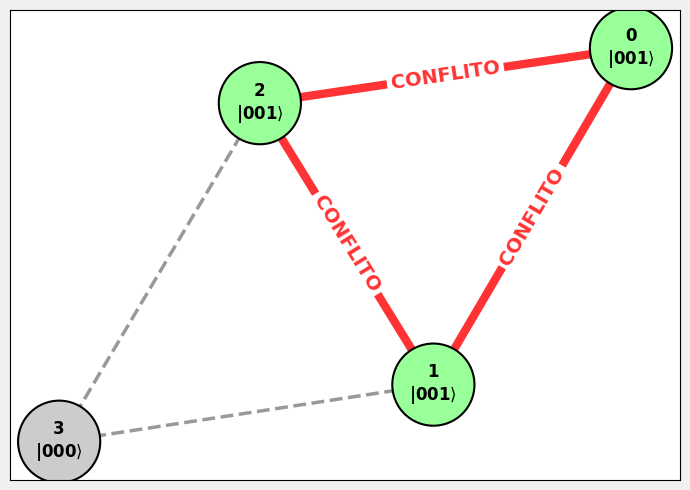

In [14]:
penalty = 2
k_coloring = partial(graph_coloring_h, edges, num_nodes, num_colors, penalty)

res, result = qaoa(
    problem_h=k_coloring,
    mixer_h=default_mixer_h,
    initial_state=H,
    num_qubits=num_nodes * num_colors,
    p=4,
)

print(res)
display(result.histogram("bin", hamiltonian=k_coloring))

plot_k_coloring_graph(
    edges,
    num_nodes,
    num_colors,
    result.most_frequent_state(),
)

## Mixer XY no Espaço One-Hot

Se utilizarmos o Hamiltoniano de mistura padrão $\sum X_i$ neste problema, teremos um grande obstáculo. O operador Pauli-X atua invertendo os qubits individualmente (flip de bits).

Ao aplicar $e^{-i\beta X}$ a um estado válido como $|100\rangle$, ele criará superposições com estados inválidos, como $|110\rangle$ (um vértice com duas cores simultâneas) ou $|000\rangle$ (um vértice sem cor). Isso expande o espaço de busca do algoritmo de $k^n$ (apenas estados válidos) para $2^{nk}$ (todo o espaço de Hilbert), tornando a otimização extremamente ineficiente e exigindo um número massivo de camadas $p$ para tentar forçar o sistema a voltar para estados válidos.

Para garantir que o algoritmo só explore configurações válidas (onde cada vértice tem exatamente uma cor), utilizamos o **Mixer XY** (também conhecido como _Ring Mixer_).

O operador de evolução do Mixer XY atua em pares de qubits trocando os estados $|01\rangle \leftrightarrow |10\rangle$ e deixando $|00\rangle$ e $|11\rangle$ inalterados. Matematicamente, para dois qubits $i$ e $j$, ele é definido como:

$$H_{XY} = \frac{1}{2} (X_i X_j + Y_i Y_j)$$

**Como aplicamos no QAOA:**

Conectamos os $k$ qubits de um _mesmo vértice_ em uma topologia de anel (o qubit 1 se conecta ao 2, o 2 ao 3, ..., e o último volta ao 1). Ao aplicar o Mixer XY nesse anel, o único estado $|1\rangle$ (a "cor" atual do vértice) pode "saltar" para a posição vizinha, criando uma superposição de cores válidas, sem nunca criar uma segunda cor ou destruir a existente.


In [15]:
def xy_mixer_h(qubits: Quant) -> Hamiltonian:
    """XY-Mixer Hamiltonian"""

    n = len(qubits)
    ring = [(i, (i + 1) % n) for i in range(n)]

    with obs():
        return sum(X(i) * X(j) + Y(i) * Y(j) for i, j in map(qubits.at, ring)) / 2


def graph_coloring_mixer_h(
    num_nodes: int,
    num_colors: int,
    qubits: Quant,
) -> Hamiltonian:

    qubits = [qubits[i * num_colors : (i + 1) * num_colors] for i in range(num_nodes)]

    return sum(xy_mixer_h(node) for node in qubits)

## Optimizando a Coloração

Para rodar essa versão restrita do QAOA, a função `initial_state` que passamos para o nosso Ansatz agnóstico não pode mais ser uma simples camada de portas Hadamard ($H$). Precisamos preparar um estado inicial que já seja um One-Hot válido para cada vértice (por exemplo, usando a função `w` da biblioteca `ket.qulib.prepare` com 1 excitação, ou simplesmente inicializando a primeira cor com uma porta $X$).


In [16]:
def graph_coloring_initial_state(
    num_nodes: int,
    num_colors: int,
    qubits: Quant,
):
    qubits = [qubits[i * num_colors : (i + 1) * num_colors] for i in range(num_nodes)]
    for node in qubits:
        qulib.prepare.w(node)


process = Process()
qubits = [process.alloc(num_colors) for _ in range(num_nodes)]
graph_coloring_initial_state(num_nodes, num_colors, reduce(add, qubits))
dump(*qubits).show()

<IPython.core.display.Math object>

 message: Return from COBYLA because the trust region radius reaches its lower bound.
 success: True
  status: 0
     fun: 0.42168663486595914
       x: [ 6.968e-01  3.466e-01  1.866e-01  5.908e-01  5.883e-01
            1.136e+00  4.006e-01  2.710e-01  3.786e-01  1.623e-02
           -2.396e-01 -1.799e-01]
    nfev: 703
   maxcv: 0.0


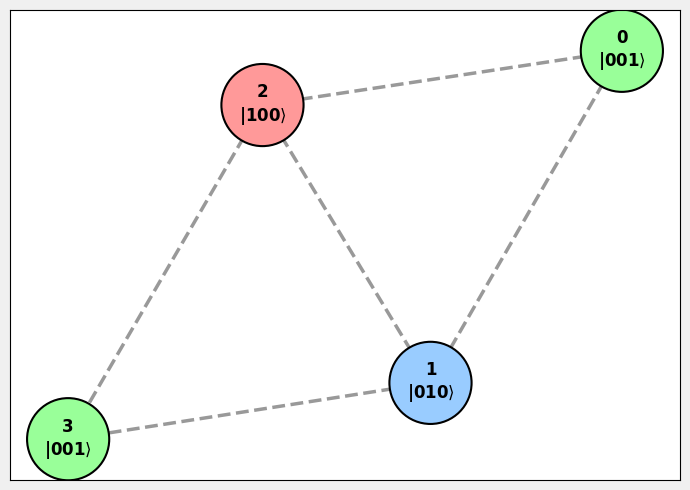

In [17]:
penalty = 0
k_coloring = partial(graph_coloring_h, edges, num_nodes, num_colors, penalty)

res, result = qaoa(
    problem_h=k_coloring,
    mixer_h=partial(graph_coloring_mixer_h, num_nodes, num_colors),
    initial_state=partial(graph_coloring_initial_state, num_nodes, num_colors),
    num_qubits=num_nodes * num_colors,
    p=4,
)

print(res)
display(result.histogram("bin", hamiltonian=k_coloring))

plot_k_coloring_graph(
    edges,
    num_nodes,
    num_colors,
    result.most_frequent_state(),
)

# 📚 Material Complementar

Para aprofundar seus conhecimentos nos conceitos teóricos e práticos abordados neste notebook, recomendamos os seguintes materiais:

## [Plataforma Aprenda Ket](https://aprenda.quantumket.org)

Uma excelente introdução em português, ideal para construir uma base sólida desde os conceitos mais básicos:

* **[Computação Quântica](https://aprenda.quantumket.org/07-computacao_quantica.html):** Uma visão geral sobre circuitos quânticos.
* **[Algoritmos Variacionais Quânticos](https://aprenda.quantumket.org/algoritmos/variacionais/09_4_0-algoritmos_variacionais.html):** Algoritmos de optimização quântica.

## [Ket Programming Guide](https://quantumket.org/guide/index.html)

* O guia de programação oficial do Ket. Apesar de estar em inglês, é um material prático e muito bem estruturado para entender a fundo como programar utilizando a plataforma.
* **[Otimização Quântica](https://quantumket.org/tutorials/quantum-optimization.html)**: Resolvendo Max-Cut com QAOA, VQE e FALQON
